In [1]:
from pathlib import Path
import sys

if Path('/content').exists():
    ROOT = Path('/content/woodbench')
else:
    ROOT = Path.cwd().parent.parent.parent

sys.path.insert(0, str(ROOT))
ROOT

PosixPath('/workspace/woodbench')

# Phase 1B — Probe phá thông tin giải phẫu

Notebook kiểm tra liệu strict-17 có thể được giải bằng tín hiệu không cần cấu trúc tế bào. Ba probe dùng cùng split và seed 42:

- **B1:** resize 224→16→224 bằng bilinear;
- **B2:** Gaussian blur 49×49, sigma 8;
- **B3:** bỏ CNN, histogram RGB 3×32 bin (96-D) → MLP hai lớp.

B1–B2 dùng Swin-T ImageNet pretrained và full fine-tuning. Notebook chỉ train B1–B3. Dòng `Full-image baseline` trong bảng được đọc từ artifact strict-17 đã tính lại bằng metric chuẩn và chỉ đóng vai trò tham chiếu. Checkpoint, prediction và bảng đều được ghi vào `artifacts/phase_1b/anatomy_destruction_probe/`.


In [2]:
if Path('/content').exists():
    !pip install -q -r {ROOT}/requirements.txt


In [2]:
import gc
import json
import math
import multiprocessing as mp
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from PIL import Image, ImageOps
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode, functional as TF

from src.data.dataset import FlatConiferDataset
from src.eval.metrics import TASK_B_LABELS, TASK_B_NUM_CLASSES, compute_task_b_metrics
from src.models import create_model
from src.train import create_loss_function, create_optimizer, create_scheduler
from src.utils import set_seed

DATA_ROOT = ROOT / 'data' / 'task-B-group-split'
ARTIFACT_DIR = ROOT / 'artifacts' / 'phase_1b' / 'anatomy_destruction_probe'
CHECKPOINT_DIR = ARTIFACT_DIR / 'checkpoints'
PREDICTION_DIR = ARTIFACT_DIR / 'predictions'
TABLE_DIR = ARTIFACT_DIR / 'tables'
FIGURE_DIR = ARTIFACT_DIR / 'figures'
BASELINE_METRICS_PATH = (
    ROOT / 'artifacts' / 'phase_1b' / 'best_checkpoint_evaluation'
    / 'main' / 'seed_42' / 'swin_tiny' / 'metrics.json'
)
BASELINE_CLASS_NAMES_PATH = BASELINE_METRICS_PATH.with_name('class_names.json')
for directory in [ARTIFACT_DIR, CHECKPOINT_DIR, PREDICTION_DIR, TABLE_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42
EPOCHS = 20
IMAGE_SIZE = 224
SWIN_BATCH_SIZE = 32
HISTOGRAM_BATCH_SIZE = 128
NUM_WORKERS = 2 if torch.cuda.is_available() else 0
LABEL_SMOOTHING = 0.1
HEAD_LR = 1e-4
BACKBONE_LR = 1e-5
MLP_LR = 1e-3
WEIGHT_DECAY = 1e-4
STOP_THRESHOLD_PERCENT = 60.0
FORCE_RETRAIN = False
PARALLEL_PROBES = True
PARALLEL_VARIANTS = ('B1_16px', 'B2_blur8', 'B3_rgb_histogram')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EXPECTED_COUNTS = {'train': 3365, 'val': 903, 'test': 532}
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
VARIANTS = {
    'B1_16px': {'model': 'swin_tiny', 'description': 'Resize 224->16->224 bilinear'},
    'B2_blur8': {'model': 'swin_tiny', 'description': 'Gaussian blur kernel=49 sigma=8'},
    'B3_rgb_histogram': {'model': 'mlp_96_128_17', 'description': 'RGB 3x32-bin histogram'},
}
set_seed(SEED)
print(f'Device={DEVICE}; artifacts={ARTIFACT_DIR.relative_to(ROOT)}')


Device=cuda; artifacts=artifacts/phase_1b/anatomy_destruction_probe


## 5.0. Xác nhận strict split và class universe

Mọi cấu hình phải dùng đúng cùng 17 lớp và cùng ánh xạ label. Test chỉ được dùng sau khi đã chọn best epoch bằng validation macro-F1.


In [3]:
CLASS_NAMES = sorted(path.name for path in (DATA_ROOT / 'train').iterdir() if path.is_dir())
assert len(CLASS_NAMES) == TASK_B_NUM_CLASSES == 17
assert tuple(TASK_B_LABELS) == tuple(range(17))
for split in ('train', 'val', 'test'):
    split_classes = sorted(path.name for path in (DATA_ROOT / split).iterdir() if path.is_dir())
    assert split_classes == CLASS_NAMES, f'{split} class mapping drift'
    count = sum(
        1 for path in (DATA_ROOT / split).rglob('*')
        if path.is_file() and path.suffix.lower() in {'.png', '.jpg', '.jpeg'}
    )
    assert count == EXPECTED_COUNTS[split], (split, count)
print(CLASS_NAMES)
print(EXPECTED_COUNTS)


['Araucaria araucana', 'Callitris columellaris', 'Calocedrus rupestris', 'Chamaecyparis obtusa', 'Cryptomeria japonica', 'Cunninghamia lanceolata', 'Fokienia hodginsii', 'Picea glauca', 'Pinus cernua', 'Pinus dalatensis', 'Pinus krempfii', 'Pinus radiata', 'Podocarpus pilgeri', 'Pseudotsuga brevifolia', 'Taxus wallichiana', 'Thujopsis dolabrata', 'Xanthocyparis vietnamensis']
{'train': 3365, 'val': 903, 'test': 532}


## 5.1. Biến đổi B1–B3

B1/B2 được đặt sau augmentation hình học/ColorJitter và trước tensor normalization. Cùng phép phá được áp dụng ở train, validation và test; nếu chỉ phá test thì thí nghiệm sẽ đo domain shift thay vì khả năng học shortcut. B3 tính histogram trên RGB `[0,1]` trước ImageNet normalization và loại bỏ toàn bộ bố cục không gian.


In [4]:
class RGBHistogramTransform:
    def __init__(self, bins=32):
        self.bins = bins

    def __call__(self, image):
        tensor = TF.pil_to_tensor(image).float().div(255.0)
        histograms = []
        for channel in tensor:
            histogram = torch.histc(channel, bins=self.bins, min=0.0, max=1.0)
            histogram = histogram / histogram.sum().clamp_min(1.0)
            histograms.append(histogram)
        return torch.cat(histograms, dim=0)


def common_train_prefix():
    return [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(degrees=30.0),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
    ]


def corruption_ops(variant):
    if variant == 'B1_16px':
        return [
            transforms.Resize(
                (16, 16), interpolation=InterpolationMode.BILINEAR, antialias=True
            ),
            transforms.Resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                interpolation=InterpolationMode.BILINEAR, antialias=True,
            ),
        ]
    if variant == 'B2_blur8':
        return [transforms.GaussianBlur(kernel_size=49, sigma=(8.0, 8.0))]
    if variant == 'B3_rgb_histogram':
        return []
    raise ValueError(variant)


def make_transform(variant, train):
    prefix = common_train_prefix() if train else [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))
    ]
    operations = prefix + corruption_ops(variant)
    if variant == 'B3_rgb_histogram':
        operations.append(RGBHistogramTransform(bins=32))
    else:
        operations.extend([
            transforms.ToTensor(),
            transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ])
    return transforms.Compose(operations)


def make_loaders(variant):
    train_dataset = FlatConiferDataset(
        DATA_ROOT, split='train', transform=make_transform(variant, True),
        task='taskB', classes=CLASS_NAMES,
    )
    val_dataset = FlatConiferDataset(
        DATA_ROOT, split='val', transform=make_transform(variant, False),
        task='taskB', classes=CLASS_NAMES,
    )
    test_dataset = FlatConiferDataset(
        DATA_ROOT, split='test', transform=make_transform(variant, False),
        task='taskB', classes=CLASS_NAMES,
    )
    assert [len(train_dataset), len(val_dataset), len(test_dataset)] == [
        EXPECTED_COUNTS['train'], EXPECTED_COUNTS['val'], EXPECTED_COUNTS['test']
    ]
    batch_size = HISTOGRAM_BATCH_SIZE if variant == 'B3_rgb_histogram' else SWIN_BATCH_SIZE
    # A loky worker must not start another multiprocessing pool for DataLoader.
    # Nested process creation mixes loky's Process/Popen classes with PyTorch and
    # fails with `AttributeError: Process object has no attribute env`.
    loader_num_workers = 0 if mp.parent_process() is not None else NUM_WORKERS
    generator = torch.Generator().manual_seed(SEED)
    common = dict(
        batch_size=batch_size, num_workers=loader_num_workers,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=loader_num_workers > 0,
    )
    train_loader = DataLoader(
        train_dataset, shuffle=True, drop_last=True, generator=generator, **common
    )
    val_loader = DataLoader(val_dataset, shuffle=False, drop_last=False, **common)
    test_loader = DataLoader(test_dataset, shuffle=False, drop_last=False, **common)
    return train_loader, val_loader, test_loader


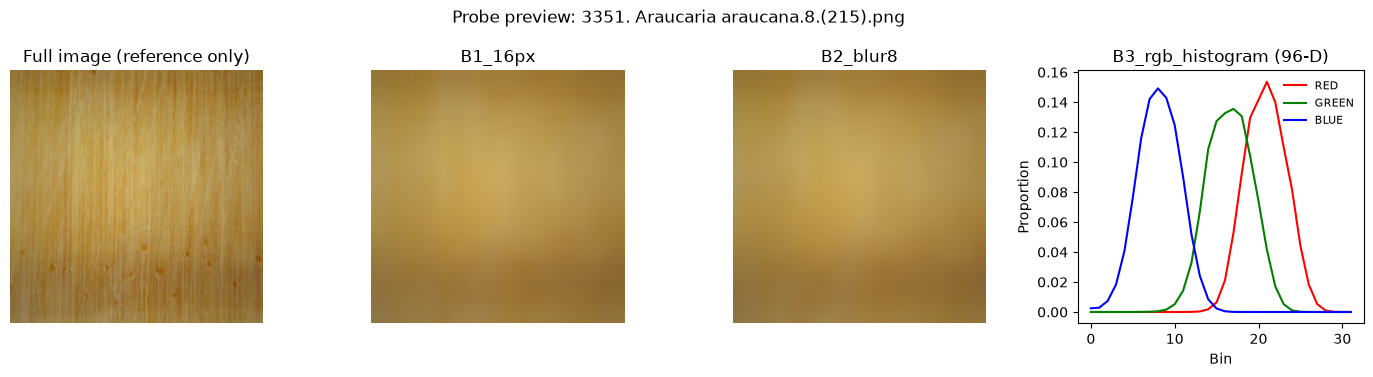

In [5]:
preview_path = sorted((DATA_ROOT / 'test').rglob('*.png'))[0]
with Image.open(preview_path) as image:
    preview_image = ImageOps.exif_transpose(image).convert('RGB')
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
axes[0].imshow(transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))(preview_image))
axes[0].set_title('Full image (reference only)')
axes[0].axis('off')
for axis, variant in zip(axes[1:3], ['B1_16px', 'B2_blur8']):
    operations = transforms.Compose(
        [transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))] + corruption_ops(variant)
    )
    axis.imshow(operations(preview_image))
    axis.set_title(variant)
    axis.axis('off')
histogram = RGBHistogramTransform(32)(preview_image).reshape(3, 32).numpy()
for channel, color in enumerate(['red', 'green', 'blue']):
    axes[3].plot(histogram[channel], color=color, label=color.upper())
axes[3].set_title('B3_rgb_histogram (96-D)')
axes[3].set_xlabel('Bin')
axes[3].set_ylabel('Proportion')
axes[3].legend(frameon=False, fontsize=8)
fig.suptitle(f'Probe preview: {preview_path.name}')
fig.tight_layout()
preview_output = FIGURE_DIR / 'probe_input_preview.png'
fig.savefig(preview_output, dpi=300, bbox_inches='tight')
plt.show()


## 5.2. Model và training contract

B1–B2 tạo Swin-T mới từ ImageNet cho từng probe; không warm-start từ experiment cũ. B3 là `Linear(96,128)→ReLU→Dropout→Linear(128,17)`. Mỗi probe chạy đủ 20 epoch, lưu best checkpoint theo validation macro-F1, rồi mới đánh giá test đúng một lần.


In [6]:
class ColorHistogramMLP(nn.Module):
    def __init__(self, input_dim=96, hidden_dim=128, num_classes=17):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.2),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, features):
        return self.network(features)


def make_model_and_training_objects(variant, pretrained=True):
    if variant == 'B3_rgb_histogram':
        model = ColorHistogramMLP(num_classes=TASK_B_NUM_CLASSES)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=MLP_LR, weight_decay=WEIGHT_DECAY
        )
    else:
        model = create_model(
            'swin_tiny', num_classes=TASK_B_NUM_CLASSES, pretrained=pretrained
        )
        optimizer = create_optimizer(
            model, lr=HEAD_LR, backbone_lr=BACKBONE_LR,
            weight_decay=WEIGHT_DECAY,
        )
    scheduler = create_scheduler(
        optimizer, epochs=EPOCHS, scheduler_type='cosine', warmup_epochs=5
    )
    criterion = create_loss_function(
        'label_smoothing', label_smoothing=LABEL_SMOOTHING
    )
    return model.to(DEVICE), optimizer, scheduler, criterion.to(DEVICE)


In [7]:
def serializable_metrics(metrics):
    return {
        key: value for key, value in metrics.items()
        if key not in {'confusion_matrix'}
    }


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_examples = 0
    all_true = []
    all_pred = []
    for inputs, labels in loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        logits = model(inputs)
        loss = criterion(logits, labels)
        total_loss += float(loss.item()) * len(labels)
        total_examples += len(labels)
        all_true.extend(labels.cpu().numpy().tolist())
        all_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
    metrics = compute_task_b_metrics(
        np.asarray(all_true), np.asarray(all_pred), class_names=CLASS_NAMES
    )
    metrics['loss'] = total_loss / total_examples
    return metrics, np.asarray(all_true), np.asarray(all_pred)


def train_one_epoch(model, loader, optimizer, criterion, scaler):
    model.train()
    total_loss = 0.0
    total_examples = 0
    all_true = []
    all_pred = []
    for inputs, labels in loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=DEVICE.type == 'cuda'):
            logits = model(inputs)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += float(loss.item()) * len(labels)
        total_examples += len(labels)
        all_true.extend(labels.cpu().numpy().tolist())
        all_pred.extend(logits.argmax(dim=1).detach().cpu().numpy().tolist())
    metrics = compute_task_b_metrics(
        np.asarray(all_true), np.asarray(all_pred), class_names=CLASS_NAMES
    )
    metrics['loss'] = total_loss / total_examples
    return metrics


def checkpoint_payload(variant, epoch, model, optimizer, scheduler, history, best_val_f1):
    return {
        'variant': variant, 'epoch': epoch, 'seed': SEED, 'epochs': EPOCHS,
        'class_names': CLASS_NAMES, 'metric_labels': list(TASK_B_LABELS),
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'history': history, 'best_val_f1': best_val_f1,
        'loaded_from_experiments': False,
    }


def train_variant(variant):
    set_seed(SEED)
    variant_dir = CHECKPOINT_DIR / variant
    variant_dir.mkdir(parents=True, exist_ok=True)
    best_path = variant_dir / 'best.pt'
    last_path = variant_dir / 'last.pt'
    metrics_path = TABLE_DIR / f'{variant}_test_metrics.json'
    if best_path.exists() and metrics_path.exists() and not FORCE_RETRAIN:
        print(f'Skip completed variant: {variant}')
        return json.loads(metrics_path.read_text(encoding='utf-8'))

    train_loader, val_loader, test_loader = make_loaders(variant)
    model, optimizer, scheduler, criterion = make_model_and_training_objects(
        variant, pretrained=FORCE_RETRAIN or not last_path.exists()
    )
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type == 'cuda')
    history = []
    start_epoch = 0
    best_val_f1 = -math.inf
    if last_path.exists() and not FORCE_RETRAIN:
        checkpoint = torch.load(last_path, map_location=DEVICE, weights_only=False)
        assert checkpoint['class_names'] == CLASS_NAMES
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        history = checkpoint['history']
        best_val_f1 = float(checkpoint['best_val_f1'])
        start_epoch = int(checkpoint['epoch']) + 1
        print(f'Resume {variant} from epoch {start_epoch + 1}')

    for epoch in range(start_epoch, EPOCHS):
        train_metrics = train_one_epoch(model, train_loader, optimizer, criterion, scaler)
        val_metrics, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step()
        row = {
            'epoch': epoch + 1,
            'train_loss': train_metrics['loss'],
            'train_accuracy': train_metrics['accuracy'],
            'train_f1_macro': train_metrics['f1_macro'],
            'val_loss': val_metrics['loss'],
            'val_accuracy': val_metrics['accuracy'],
            'val_f1_macro': val_metrics['f1_macro'],
            'head_lr': optimizer.param_groups[0]['lr'],
        }
        history.append(row)
        if val_metrics['f1_macro'] > best_val_f1:
            best_val_f1 = float(val_metrics['f1_macro'])
            torch.save(
                checkpoint_payload(
                    variant, epoch, model, optimizer, scheduler, history, best_val_f1
                ),
                best_path,
            )
        torch.save(
            checkpoint_payload(
                variant, epoch, model, optimizer, scheduler, history, best_val_f1
            ),
            last_path,
        )
        pd.DataFrame(history).to_csv(TABLE_DIR / f'{variant}_history.csv', index=False)
        print(
            f"{variant} epoch {epoch + 1:02d}/{EPOCHS}: "
            f"train_acc={train_metrics['accuracy'] * 100:.2f}% "
            f"val_acc={val_metrics['accuracy'] * 100:.2f}% "
            f"val_f1={val_metrics['f1_macro'] * 100:.2f}%"
        )

    best_checkpoint = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(best_checkpoint['model_state_dict'])
    test_metrics, y_true, y_pred = evaluate(model, test_loader, criterion)
    np.save(PREDICTION_DIR / f'{variant}_y_true.npy', y_true)
    np.save(PREDICTION_DIR / f'{variant}_y_pred.npy', y_pred)
    payload = {
        'variant': variant, 'seed': SEED, 'epochs': EPOCHS,
        'best_epoch': int(best_checkpoint['epoch']) + 1,
        'best_val_f1_macro': float(best_checkpoint['best_val_f1']),
        'test_accuracy': float(test_metrics['accuracy']),
        'test_f1_macro': float(test_metrics['f1_macro']),
        'test_precision_macro': float(test_metrics['precision_macro']),
        'test_recall_macro': float(test_metrics['recall_macro']),
        'class_names': CLASS_NAMES, 'metric_labels': list(TASK_B_LABELS),
        'per_class': test_metrics['per_class'],
        'loaded_from_experiments': False,
    }
    metrics_path.write_text(
        json.dumps(payload, indent=2, ensure_ascii=False), encoding='utf-8'
    )
    del model, optimizer, scheduler, criterion, train_loader, val_loader, test_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return payload


## 5.3. Chạy B1–B3

> Trên máy có RTX 4090, cell này mặc định chạy đồng thời đúng ba probe B1, B2 và B3 bằng ba process độc lập. Mỗi variant có checkpoint riêng và resume từ `last.pt`. Nếu thiếu VRAM, đặt `PARALLEL_PROBES = False` để chạy tuần tự.


In [9]:
if PARALLEL_PROBES and DEVICE.type == 'cuda':
    print(f'Parallel launch on {torch.cuda.get_device_name(0)}: {PARALLEL_VARIANTS}')
    # Populate the ImageNet cache once in the parent process. This prevents B1 and
    # B2 from trying to download/write the same pretrained file concurrently.
    cache_model = create_model(
        'swin_tiny', num_classes=TASK_B_NUM_CLASSES, pretrained=True
    )
    del cache_model
    gc.collect()
    parallel_results = Parallel(
        n_jobs=len(PARALLEL_VARIANTS), backend='loky', verbose=10,
        batch_size=1, pre_dispatch='all',
    )(delayed(train_variant)(variant) for variant in PARALLEL_VARIANTS)
else:
    mode_reason = 'PARALLEL_PROBES=False' if DEVICE.type == 'cuda' else 'CUDA unavailable'
    print(f'Sequential B1-B3 execution: {mode_reason}')
    parallel_results = [train_variant(variant) for variant in PARALLEL_VARIANTS]

results_by_variant = {result['variant']: result for result in parallel_results}
probe_results = [results_by_variant[variant] for variant in VARIANTS]
print('All probes complete:', [result['variant'] for result in probe_results])


Parallel launch on NVIDIA GeForce RTX 4090: ('B1_16px', 'B2_blur8', 'B3_rgb_histogram')


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.


B3_rgb_histogram epoch 01/20: train_acc=6.85% val_acc=7.64% val_f1=0.84%
B1_16px epoch 01/20: train_acc=7.47% val_acc=4.98% val_f1=2.34%
B2_blur8 epoch 01/20: train_acc=5.24% val_acc=7.31% val_f1=3.06%
B3_rgb_histogram epoch 02/20: train_acc=6.91% val_acc=7.64% val_f1=0.84%
B1_16px epoch 02/20: train_acc=39.52% val_acc=65.45% val_f1=62.58%
B2_blur8 epoch 02/20: train_acc=41.67% val_acc=60.13% val_f1=56.74%
B3_rgb_histogram epoch 03/20: train_acc=6.88% val_acc=7.64% val_f1=0.84%
B1_16px epoch 03/20: train_acc=71.82% val_acc=74.20% val_f1=72.54%
B2_blur8 epoch 03/20: train_acc=74.26% val_acc=73.20% val_f1=71.09%
B3_rgb_histogram epoch 04/20: train_acc=8.68% val_acc=15.73% val_f1=8.09%
B1_16px epoch 04/20: train_acc=80.71% val_acc=77.19% val_f1=76.25%
B2_blur8 epoch 04/20: train_acc=82.65% val_acc=77.96% val_f1=77.58%
B3_rgb_histogram epoch 05/20: train_acc=19.20% val_acc=30.12% val_f1=18.06%
B1_16px epoch 05/20: train_acc=83.57% val_acc=80.51% val_f1=78.91%
B2_blur8 epoch 05/20: train_ac

[Parallel(n_jobs=3)]: Done   1 out of   3 | elapsed: 171.0min remaining: 341.9min


B2_blur8 epoch 19/20: train_acc=99.05% val_acc=91.25% val_f1=91.00%
B1_16px epoch 20/20: train_acc=98.84% val_acc=91.92% val_f1=91.78%
B2_blur8 epoch 20/20: train_acc=99.35% val_acc=91.81% val_f1=91.71%
All probes complete: ['B1_16px', 'B2_blur8', 'B3_rgb_histogram']


[Parallel(n_jobs=3)]: Done   3 out of   3 | elapsed: 182.6min finished


## 5.4. Bảng nộp, baseline ngẫu nhiên và tiêu chí dừng


In [10]:
import json

probe_results = []
missing_files = []

for variant in VARIANTS:
    metrics_path = TABLE_DIR / f"{variant}_test_metrics.json"

    if metrics_path.exists():
        probe_results.append(
            json.loads(metrics_path.read_text(encoding="utf-8"))
        )
    else:
        missing_files.append(metrics_path)

if missing_files:
    raise FileNotFoundError(
        "Không tìm thấy kết quả:\n"
        + "\n".join(map(str, missing_files))
    )

print("Loaded probes:", [r["variant"] for r in probe_results])

Loaded probes: ['B1_16px', 'B2_blur8', 'B3_rgb_histogram']


,variant,input,model,accuracy_percent,macro_f1_percent,best_epoch,accuracy_retention_vs_full_baseline_percent,macro_f1_retention_vs_full_baseline_percent,stop_trigger_accuracy_gt_60
0,Uniform chance,No image,Random 1/17,5.882353,5.882353,NaN,NaN,NaN,False
1,Majority baseline,No image,Always Fokienia hodginsii,7.330827,0.803544,NaN,NaN,NaN,False
2,Full-image baseline,Full 224x224 image,"Existing strict-17 Swin-T, seed 42",99.060150,99.134761,7.0,NaN,NaN,False
3,B1_16px,Resize 224->16->224 bilinear,swin_tiny,94.360902,94.209816,16.0,95.256167,95.032071,True
4,B2_blur8,Gaussian blur kernel=49 sigma=8,swin_tiny,95.676692,95.732765,18.0,96.584440,96.568311,True
5,B3_rgb_histogram,RGB 3x32-bin histogram,mlp_96_128_17,37.969925,29.889043,17.0,38.330171,30.149912,False


### STOP: B1/B2 còn vượt 60%; benchmark chính thức chưa dùng được.

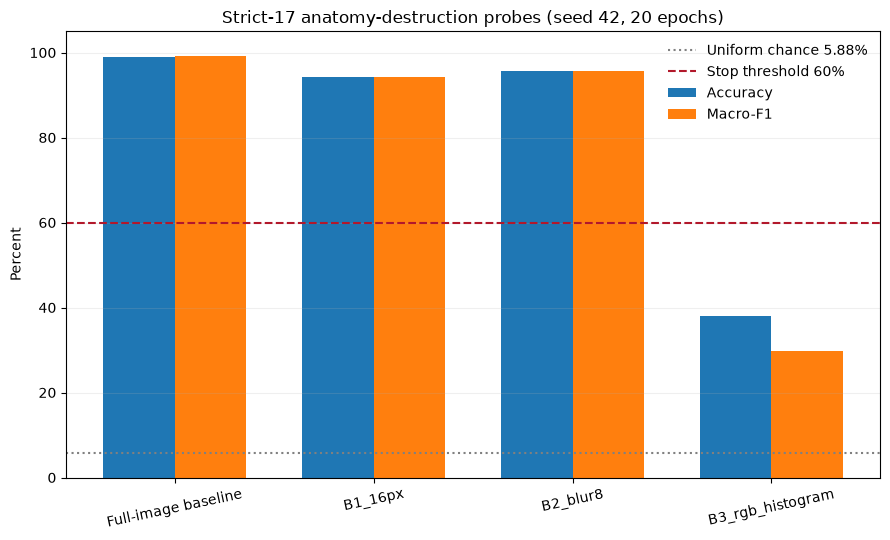

In [11]:
_, _, reference_test_loader = make_loaders('B3_rgb_histogram')
test_labels = np.asarray([label for _, label in reference_test_loader.dataset.samples])
majority_label = int(np.bincount(test_labels, minlength=17).argmax())
majority_pred = np.full_like(test_labels, majority_label)
majority_metrics = compute_task_b_metrics(
    test_labels, majority_pred, class_names=CLASS_NAMES
)
chance_percent = 100.0 / TASK_B_NUM_CLASSES
baseline_metrics = json.loads(BASELINE_METRICS_PATH.read_text(encoding='utf-8'))
baseline_class_names = json.loads(
    BASELINE_CLASS_NAMES_PATH.read_text(encoding='utf-8')
)
assert baseline_metrics['num_classes'] == TASK_B_NUM_CLASSES
assert baseline_metrics['test_images'] == EXPECTED_COUNTS['test']
assert baseline_class_names == CLASS_NAMES

summary_rows = [
    {
        'variant': 'Uniform chance', 'input': 'No image', 'model': 'Random 1/17',
        'accuracy_percent': chance_percent, 'macro_f1_percent': chance_percent,
        'best_epoch': np.nan,
    },
    {
        'variant': 'Majority baseline', 'input': 'No image',
        'model': f'Always {CLASS_NAMES[majority_label]}',
        'accuracy_percent': majority_metrics['accuracy'] * 100,
        'macro_f1_percent': majority_metrics['f1_macro'] * 100,
        'best_epoch': np.nan,
    },
    {
        'variant': 'Full-image baseline', 'input': 'Full 224x224 image',
        'model': 'Existing strict-17 Swin-T, seed 42',
        'accuracy_percent': baseline_metrics['accuracy'] * 100,
        'macro_f1_percent': baseline_metrics['f1_macro'] * 100,
        'best_epoch': baseline_metrics['best_epoch'],
    },
]
for result in probe_results:
    variant = result['variant']
    summary_rows.append({
        'variant': variant, 'input': VARIANTS[variant]['description'],
        'model': VARIANTS[variant]['model'],
        'accuracy_percent': result['test_accuracy'] * 100,
        'macro_f1_percent': result['test_f1_macro'] * 100,
        'best_epoch': result['best_epoch'],
    })
summary = pd.DataFrame(summary_rows)
baseline_accuracy = baseline_metrics['accuracy'] * 100
baseline_f1 = baseline_metrics['f1_macro'] * 100
summary['accuracy_retention_vs_full_baseline_percent'] = np.where(
    summary['variant'].isin(VARIANTS),
    summary['accuracy_percent'] / baseline_accuracy * 100, np.nan,
)
summary['macro_f1_retention_vs_full_baseline_percent'] = np.where(
    summary['variant'].isin(VARIANTS),
    summary['macro_f1_percent'] / baseline_f1 * 100, np.nan,
)
summary['stop_trigger_accuracy_gt_60'] = (
    summary['variant'].isin(['B1_16px', 'B2_blur8'])
    & summary['accuracy_percent'].gt(STOP_THRESHOLD_PERCENT)
)
summary.to_csv(TABLE_DIR / 'anatomy_probe_summary.csv', index=False)
display(summary)

stop_triggered = bool(summary['stop_trigger_accuracy_gt_60'].any())
status = (
    'STOP: B1/B2 còn vượt 60%; benchmark chính thức chưa dùng được.'
    if stop_triggered
    else 'PASS HEURISTIC: B1/B2 không vượt 60%; vẫn cần đọc retention và per-class F1.'
)
display(Markdown(f'### {status}'))

comparison_order = ['Full-image baseline', *VARIANTS]
x = np.arange(len(comparison_order))
probe_only = summary.set_index('variant').loc[comparison_order]
fig, ax = plt.subplots(figsize=(9, 5.5))
width = 0.36
ax.bar(x - width / 2, probe_only['accuracy_percent'], width, label='Accuracy')
ax.bar(x + width / 2, probe_only['macro_f1_percent'], width, label='Macro-F1')
ax.axhline(chance_percent, color='gray', linestyle=':', label='Uniform chance 5.88%')
ax.axhline(STOP_THRESHOLD_PERCENT, color='#b2182b', linestyle='--', label='Stop threshold 60%')
ax.set_xticks(x, comparison_order, rotation=12)
ax.set_ylabel('Percent')
ax.set_ylim(0, 105)
ax.set_title('Strict-17 anatomy-destruction probes (seed 42, 20 epochs)')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'anatomy_probe_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


In [12]:
per_class_rows = []
for result in probe_results:
    for class_name, metrics in result['per_class'].items():
        per_class_rows.append({
            'variant': result['variant'], 'class_name': class_name,
            'precision': metrics['precision'], 'recall': metrics['recall'],
            'f1': metrics['f1'],
        })
per_class = pd.DataFrame(per_class_rows)
per_class.to_csv(TABLE_DIR / 'anatomy_probe_per_class_metrics.csv', index=False)
display(per_class.pivot(index='class_name', columns='variant', values='f1'))


variant,B1_16px,B2_blur8,B3_rgb_histogram
class_name,,,
Araucaria araucana,0.967742,0.967742,0.000000
Callitris columellaris,0.985075,1.000000,0.000000
Calocedrus rupestris,0.941176,0.979592,0.478261
Chamaecyparis obtusa,0.942857,0.891892,0.584270
Cryptomeria japonica,0.985075,0.985075,0.583333
Cunninghamia lanceolata,1.000000,1.000000,0.530120
Fokienia hodginsii,0.987342,1.000000,0.065574
Picea glauca,1.000000,1.000000,0.126984
Pinus cernua,0.949153,0.949153,0.000000


## Cách đọc kết quả

- B1/B2 cao: chi tiết giải phẫu không cần thiết để đạt điểm cao; benchmark có shortcut tần số thấp/specimen/capture.
- B3 cao: riêng phân phối màu đã dự đoán được loài; ưu tiên sửa thu thập/cân bằng phiên chụp thay vì đổi backbone.
- B1/B2 cao nhưng B3 thấp: shortcut có thể là gradient ánh sáng, vòng/dải lớn, vết nứt hoặc pattern specimen thay vì màu đơn thuần.
- B1/B2 thấp không tự động chứng minh model dùng đúng giải phẫu sinh học; đây chỉ là điều kiện cần thuận lợi.
- `60%` là stop threshold thực dụng, không phải kiểm định thống kê. Đọc thêm retention so với full-image baseline, majority baseline và per-class F1.


In [13]:
run_summary = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'data_root': str(DATA_ROOT.relative_to(ROOT)),
    'classes': CLASS_NAMES, 'metric_labels': list(TASK_B_LABELS),
    'seed': SEED, 'epochs': EPOCHS,
    'variants': VARIANTS,
    'parallel_probes': PARALLEL_PROBES,
    'parallel_variants': list(PARALLEL_VARIANTS),
    'swin_initialization': 'timm ImageNet pretrained; fresh per B1/B2',
    'probe_experiment_checkpoint_loaded': False,
    'full_image_baseline_metrics_source': str(BASELINE_METRICS_PATH.relative_to(ROOT)),
    'selection_rule': 'best validation macro-F1; test evaluated once',
    'uniform_chance_percent': chance_percent,
    'majority_accuracy_percent': majority_metrics['accuracy'] * 100,
    'stop_threshold_percent': STOP_THRESHOLD_PERCENT,
    'stop_triggered': stop_triggered,
    'status': status,
    'summary': summary.to_dict(orient='records'),
}
(ARTIFACT_DIR / 'run_summary.json').write_text(
    json.dumps(run_summary, indent=2, ensure_ascii=False), encoding='utf-8'
)
readme = f'''# Anatomy destruction probe artifacts

Generated by `notebooks/phase 1/investigator/WoodID_Phase1_Anatomy_Destruction_Probe.ipynb`.

- Dataset: `data/task-B-group-split`, strict 17 classes.
- Seed: {SEED}; epochs: {EPOCHS}.
- Execution: only B1/B2/B3 are trained, using three concurrent loky processes when CUDA is available.
- B1/B2: fresh ImageNet-pretrained Swin-T full fine-tuning.
- B3: normalized RGB 3x32-bin histogram and two-layer MLP.
- Full-image baseline: read from `{BASELINE_METRICS_PATH.relative_to(ROOT)}` and used only as a reference row.
- Canonical metrics: explicit labels 0..16, zero_division=0.
- Test selection: best validation macro-F1; test evaluated once.
- Experiment checkpoint loaded: false.
- Status: {status}
'''
(ARTIFACT_DIR / 'README.md').write_text(readme, encoding='utf-8')
print(f'Exported to {ARTIFACT_DIR.relative_to(ROOT)}')


Exported to artifacts/phase_1b/anatomy_destruction_probe
